# 3. Lattice constant and bulk modulus

The equilibrium lattice constant is where the energy is lowest, and the curvature of the energy against the
volume gives the bulk modulus. This tutorial computes both for silicon by fitting an equation of state, and
checks the result against the pressure that jsiesta computes directly from the stress tensor.

**You will learn** to scan a structural parameter, fit an equation of state, and use the stress as an
independent check.

Run time: about one minute.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

import jax_siesta as js

PSEUDOS = Path("../../examples/pseudos").resolve()
plt.rcParams["figure.dpi"] = 90
EV_ANG3_TO_GPA = 160.21766208


def silicon(a):
    cell = a * np.array([[0.0, 0.5, 0.5], [0.5, 0.0, 0.5], [0.5, 0.5, 0.0]])
    return js.make_structure(cell, ["Si", "Si"], [[0, 0, 0], [0.25, 0.25, 0.25]], fractional=True)

## Energy against lattice constant

One calculation object, seven structures, the same k-grid for all of them. An explicit `mesh_shape` keeps
the *number of mesh points* fixed as the cell changes, so that the curve is smooth; with a fixed cutoff the
mesh would jump from one size to the next along the scan. With symmetry on, the mesh must be compatible with
the space group: the diamond structure has operations that translate by a quarter of a lattice vector, so the
mesh size must be a multiple of 4 (jsiesta refuses a mesh that is not).

In [2]:
calc = js.Calculation.from_structure(
    silicon(5.47), PSEUDOS, basis="DZP", k_grid=(6, 6, 6), xc_functional="PBE",
    use_symmetry=True, mesh_shape=(32, 32, 32),
)
lattice = np.linspace(5.25, 5.70, 7)
volumes, energies, pressures = [], [], []
for a in lattice:
    r = calc.with_structure(silicon(a)).run()
    volumes.append(a**3 / 4.0)  # volume of the two-atom cell, Ang^3
    energies.append(r.energy_ev)
    pressures.append(r.pressure_gpa)
    print(f"a = {a:.3f} Ang   V = {volumes[-1]:7.3f} Ang^3   E = {r.energy_ev:.5f} eV   P = {r.pressure_gpa:7.3f} GPa")
volumes, energies, pressures = map(np.array, (volumes, energies, pressures))

a = 5.250 Ang   V =  36.176 Ang^3   E = -229.88804 eV   P =  14.339 GPa


a = 5.325 Ang   V =  37.748 Ang^3   E = -229.99847 eV   P =   8.740 GPa


a = 5.400 Ang   V =  39.366 Ang^3   E = -230.05682 eV   P =   3.399 GPa


a = 5.475 Ang   V =  41.029 Ang^3   E = -230.07165 eV   P =  -1.101 GPa


a = 5.550 Ang   V =  42.738 Ang^3   E = -230.04461 eV   P =  -3.744 GPa


a = 5.625 Ang   V =  44.495 Ang^3   E = -229.98318 eV   P =  -6.780 GPa


a = 5.700 Ang   V =  46.298 Ang^3   E = -229.89366 eV   P =  -9.579 GPa


## Birch-Murnaghan fit

The third-order Birch-Murnaghan equation of state has four parameters: the equilibrium energy $E_0$ and volume
$V_0$, the bulk modulus $B_0$ and its pressure derivative $B_0'$.

In [3]:
def birch_murnaghan(v, e0, v0, b0, bp):
    x = (v0 / v) ** (2.0 / 3.0)
    return e0 + 9.0 * v0 * b0 / 16.0 * ((x - 1.0) ** 3 * bp + (x - 1.0) ** 2 * (6.0 - 4.0 * x))


def bm_pressure(v, v0, b0, bp):
    x = (v0 / v) ** (1.0 / 3.0)
    return 1.5 * b0 * (x**7 - x**5) * (1.0 + 0.75 * (bp - 4.0) * (x**2 - 1.0))


guess = (energies.min(), volumes[np.argmin(energies)], 0.6, 4.0)
(e0, v0, b0, bp), _ = curve_fit(birch_murnaghan, volumes, energies, p0=guess)
a0 = (4.0 * v0) ** (1.0 / 3.0)
print(f"equilibrium lattice constant a0 = {a0:.4f} Ang")
print(f"bulk modulus B0 = {b0 * EV_ANG3_TO_GPA:.1f} GPa,  B0' = {bp:.2f}")
print(f"largest fit residual: {np.abs(birch_murnaghan(volumes, e0, v0, b0, bp) - energies).max() * 1000:.3f} meV")

equilibrium lattice constant a0 = 5.4613 Ang
bulk modulus B0 = 93.9 GPa,  B0' = 4.33
largest fit residual: 0.918 meV


For comparison: experiment gives 5.431 Ang and 99 GPa; converged plane-wave PBE calculations give about
5.47 Ang and 88 to 89 GPa. PBE overestimates lattice constants by about 1 % and underestimates bulk moduli.
The DZP basis adds an error of its own, discussed at the end.

## An independent check: the pressure from the stress tensor

The pressure is $P = -dE/dV$. jsiesta computes it analytically in every run, from the stress tensor, without
any fit. The two must agree, which tests both the stress implementation and the quality of the scan.

stress pressure minus fit pressure (GPa): [-0.036  0.348 -0.023 -0.407  0.344  0.09  -0.444]


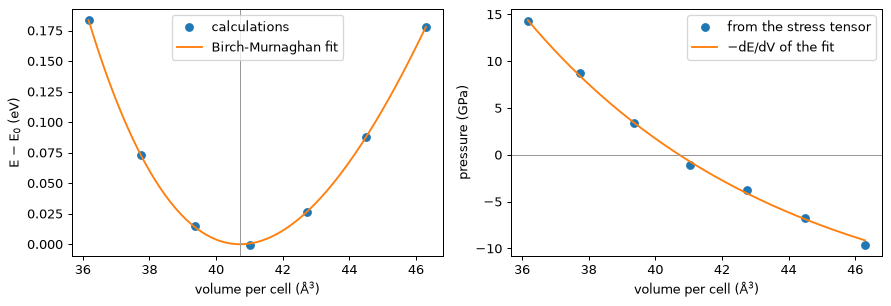

In [4]:
v_fine = np.linspace(volumes.min(), volumes.max(), 200)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(volumes, energies - e0, "o", label="calculations")
ax1.plot(v_fine, birch_murnaghan(v_fine, e0, v0, b0, bp) - e0, "-", label="Birch-Murnaghan fit")
ax1.axvline(v0, color="0.6", lw=0.8)
ax1.set_xlabel("volume per cell (Å$^3$)")
ax1.set_ylabel("E − E$_0$ (eV)")
ax1.legend()
ax2.plot(volumes, pressures, "o", label="from the stress tensor")
ax2.plot(v_fine, bm_pressure(v_fine, v0, b0, bp) * EV_ANG3_TO_GPA, "-", label="−dE/dV of the fit")
ax2.axhline(0.0, color="0.6", lw=0.8)
ax2.set_xlabel("volume per cell (Å$^3$)")
ax2.set_ylabel("pressure (GPa)")
ax2.legend()
fig.tight_layout()

diff = pressures - bm_pressure(volumes, v0, b0, bp) * EV_ANG3_TO_GPA
print("stress pressure minus fit pressure (GPa):", np.round(diff, 3))

The two agree to a few tenths of a GPa, with deviations that alternate in sign. That scatter is the mesh:
as the cell is scaled, mesh points move relative to the atoms, and the discretisation error ripples (the
egg-box effect of tutorial 2 again). With a 48 x 48 x 48 mesh the largest deviation falls from 0.44 to
0.26 GPa and the largest residual of the fit from 0.9 to 0.6 meV.

The zero of the directly computed pressure gives the lattice constant without a fit:

In [5]:
v_zero = np.interp(0.0, pressures[::-1], volumes[::-1])
print(f"P = 0 at a = {(4.0 * v_zero) ** (1.0 / 3.0):.4f} Ang (fit: {a0:.4f} Ang)")

P = 0 at a = 5.4568 Ang (fit: 5.4613 Ang)


## A note on the basis set

The orbitals have fixed radii, so compressing the crystal changes how well they fill space. This makes the
basis slightly better at small volumes and biases the equilibrium volume and the pressure (a *Pulay stress*
does not appear, since the stress is the exact derivative of the energy *for this basis*, but the basis-set
error itself depends on volume). Larger bases reduce the effect; exercise 1 measures it.

## Exercises

1. Repeat the scan with the `SZ` and `TZP` bases. How do $a_0$ and $B_0$ change? *(Solution in the Solutions
   notebook.)*
2. Replace the fixed `mesh_shape` by `mesh_cutoff_ry=150` and plot the curve again with more points. Can you
   see the discontinuities where the mesh changes size? How large are they compared with the energy scale of
   the fit?
3. Compute the cohesive energy: you need the energy of an isolated Si atom in a large box, spin-polarised
   (tutorial 6 shows spin-polarised runs). What makes that calculation delicate?
4. Apply a uniaxial strain along z to the cubic 8-atom cell and extract the elastic constant $C_{11}$ from the
   stress component $\sigma_{zz}$.